# Gradiente de Politica (Policy Gradient)
# REINFORCE

In [1]:
import random
import gymnasium as gym

import numpy as np
import collections
from tqdm import tqdm
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import os

os.environ['KMP_DUPLICATE_LIB_OK']='True'

# Reto 1
Crear una Policy Net con las siguientes caracteristicas:
* Capa de entrada lineal con funcion de activacion ReLU. El numero de neuronas esta dado por la dimension de la capa oculta.
* Capa de salida lineal con salida softmax con numero de neuronas igual a la dimension de las acciones.

In [2]:
class PolicyNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(PolicyNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim,hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim,action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc2(x), dim=1)

# Reto 2
Crear el algoritmo de REINFORCE:
* No hay $\epsilon$-greedy. Es un algoritmo tipo Monte-Carlo.
* No hay bufer de experiencias. Esn un algoritmo on-policy.

In [3]:
class REINFORCE:
    def __init__(self, state_dim, hidden_dim, action_dim, learning_rate, gamma,
                 device):
        self.policy_net = PolicyNet(state_dim, hidden_dim,
                                    action_dim).to(device)
        self.optimizer = torch.optim.Adam(self.policy_net.parameters(),
                                          lr=learning_rate)  # Optimisador Adam
        self.gamma = gamma  # factor de descuento
        self.device = device

    def take_action(self, state): # Muestreo aleatorio acorde a la distribucion de probabilidad de acciones
        state = torch.tensor([np.array(state)], dtype=torch.float).to(self.device)
        probs = self.policy_net(state) # Probabilidad de cada accion
        action_dist = torch.distributions.Categorical(probs) # Distribucion categorica de acciones
        action = action_dist.sample() # Muestrear acciones de la distribucion
        return action.item()

    def update(self, transition_dict): # Actualizar los parametros de la politica
        reward_list = transition_dict['rewards']
        state_list = transition_dict['states']
        action_list = transition_dict['actions']

        G = 0 # Retorno inicial
        self.optimizer.zero_grad()
        for i in reversed(range(len(reward_list))):  # contar desde el ultimo paso
            reward = reward_list[i]
            state = torch.tensor([state_list[i]],
                                 dtype=torch.float).to(self.device)
            action = torch.tensor([action_list[i]]).view(-1, 1).to(self.device)
            log_prob = torch.log(self.policy_net(state).gather(1, action))
            G = self.gamma * G + reward
            loss = -log_prob * G  # Funcion de perdida de cada paso
            loss.backward()  # Backpropagation
        self.optimizer.step()  # Gradiente descendente

# Reto 3
Entrenar el modelo REINFORCE en el ambiente Cart-Pole

In [4]:
learning_rate = 1e-3
num_episodes = 1000
hidden_dim = 128
gamma = 0.98
device = torch.device("cuda") if torch.cuda.is_available() else torch.device(
    "cpu")

env_name = "CartPole-v1"
env = gym.make(env_name)
env._max_episode_steps = 200
torch.manual_seed(0)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = REINFORCE(state_dim, hidden_dim, action_dim, learning_rate, gamma,
                  device)

return_list = []
for i in range(10):
    with tqdm(total=int(num_episodes / 10), desc='Iteracion %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):
            episode_return = 0
            transition_dict = {
                'states': [],
                'actions': [],
                'next_states': [],
                'rewards': [],
                'dones': []
            }
            state, _ = env.reset(seed = 0)
            done = False
            while not done:
                action = agent.take_action(state)
                next_state,reward,terminated,truncated, _ = env.step(action)
                done = terminated or truncated
                transition_dict['states'].append(state)
                transition_dict['actions'].append(action)
                transition_dict['next_states'].append(next_state)
                transition_dict['rewards'].append(reward)
                transition_dict['dones'].append(done)
                state = next_state
                episode_return += reward
            return_list.append(episode_return)
            agent.update(transition_dict)
            if (i_episode + 1) % 10 == 0:
                pbar.set_postfix({
                    'Episodio':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'Retorno':
                    '%.3f' % np.mean(return_list[-10:])
                })
            pbar.update(1)

Iteracion 0:   0%|          | 0/100 [00:00<?, ?it/s]C:\Users\Admin\AppData\Local\Temp\ipykernel_17228\102030446.py:12: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  state = torch.tensor([np.array(state)], dtype=torch.float).to(self.device)
Iteracion 9: 100%|██████████| 100/100 [00:11<00:00,  9.04it/s, Episodio=1000, Retorno=166.700]


In [5]:
def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

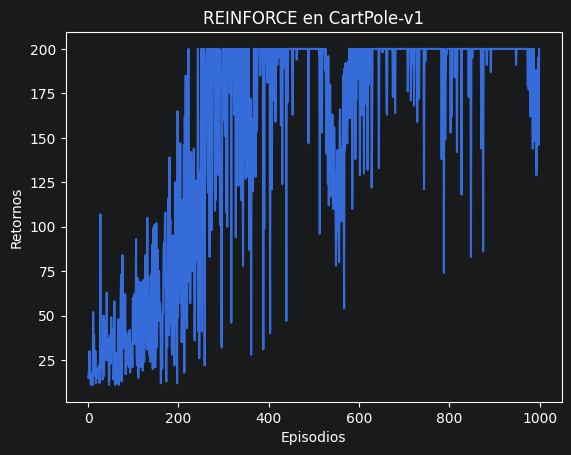

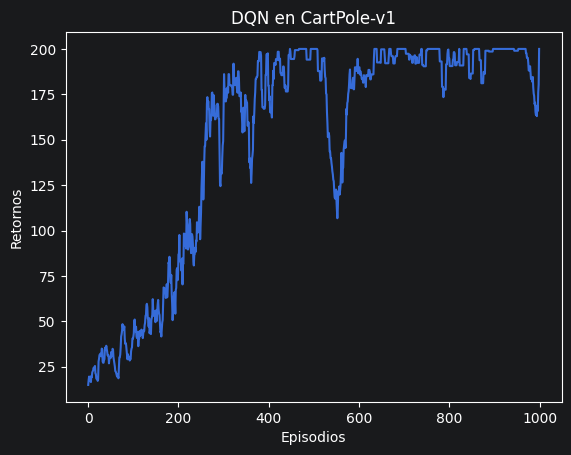

In [6]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('REINFORCE en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DQN en {}'.format(env_name))
plt.show()

# Reto 4
Pruebe la red REINFORCE entrenada en el sistema CartPole y vea lo resultados. Es bueno el modelo? Si? No? Por que?

In [10]:
#Obtener estado inicial
env = gym.make('CartPole-v1', render_mode = 'human')
for _ in range(10):
    state, _ = env.reset()
    episode_return = 0
    for step in range(500):
        with torch.no_grad():  # No necesitamos calcular gradientes en evaluación
            action = agent.take_action(state)    
        #Obtener s', r', done e info
        state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        episode_return += reward
    
        if done:
            break
    print(f'Retorno obtenido {episode_return}')
# Cerrar el ambiente
env.close()

Retorno obtenido 130.0
Retorno obtenido 181.0
Retorno obtenido 181.0
Retorno obtenido 162.0
Retorno obtenido 190.0
Retorno obtenido 115.0
Retorno obtenido 109.0
Retorno obtenido 138.0
Retorno obtenido 255.0
Retorno obtenido 154.0
